# 04. Model Training & Production Pipeline

### Overview
This module builds, trains, evaluates, and exports a production-grade machine learning pipeline for e-commerce customer churn prediction using the standardized, feature-engineered dataset.

---

### Key Workflow & Methodological Steps
1. **Empirical Feature Selection:** Drop demographic/cohort noise columns (`Country`, `Gender`, `Signup_Quarter`) showing flat churn distributions, as well as redundant collinear telemetry features (`Session_Duration_Avg`, `Pages_Per_Session`, `Mobile_App_Usage`) identified during EDA.
2. **Leakage-Free Preprocessing:** Construct a clean Scikit-learn `Pipeline` utilizing `StandardScaler` fitted strictly on the training partition and applied out-of-sample to test data.
3. **Class Imbalance Optimization:** Address class imbalance (~29% minority churn prevalence) directly via balanced algorithmic weighting (`class_weight='balanced'` and `scale_pos_weight`).
4. **Performance Evaluation:** Assess classification robustness using PR-AUC (Precision-Recall AUC), ROC-AUC, and class-specific Recall metrics.
5. **Artifact Export:** Serialize the final production pipeline into a portable `.joblib` model artifact for downstream API serving and deployment.

---

### Models Implemented
* **Baseline Benchmark:** `LogisticRegression` (with balanced class weights) to establish an interpretable linear performance floor.
* **Production Classifier:** `LGBMClassifier` (LightGBM) to capture non-linear behavioral friction interactions and complex decision boundaries.

### imports labraries and Load dataset

In [13]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report,roc_auc_score,average_precision_score
from lightgbm import LGBMClassifier

In [2]:
df = pd.read_csv("../data/feature_engineering_dataset.csv")

df.head()

,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Days_Since_Last_Purchase_is_missing,Discount_Usage_Rate_is_missing,Total_Session_Volume,Engagement_Friction_Ratio,High_Cart_Friction,Wishlist_Conversion_Ratio,Annual_Monetary_Velocity,Spend_Per_Purchase,Is_Dormant_90Days,Digital_Engagement_Composite
0,43.0,Male,France,Marseille,2.9,14.0,27.4,6.0,50.6,3.0,...,0,0,164.40,16.44,0,2.25,328.73,105.93,0,17.89
1,36.0,Male,UK,Manchester,1.6,15.0,42.7,10.3,37.7,1.0,...,0,0,439.81,54.98,0,9.75,667.17,54.74,0,26.66
2,45.0,Female,Canada,Vancouver,2.9,10.0,24.8,1.6,70.9,1.0,...,0,0,39.68,7.94,1,4.55,444.74,141.73,0,6.52
3,56.0,Female,USA,New York,2.6,10.0,38.4,14.8,41.7,9.0,...,0,0,568.32,189.44,0,1.50,900.35,156.06,0,27.82
4,35.0,Male,India,Delhi,3.1,29.0,51.4,8.4,19.1,9.0,...,0,0,431.76,215.88,0,3.25,981.06,93.58,0,40.23


### Empirical Feature Selection & Train-Test Split

In [4]:
# 1. Columns to drop based on EDA findings
# - Noise: Demographics & cohorts with flat churn rates
# - Multicollinear: Raw telemetry replaced by composite features
drop_cols = [
    # Identifiers & Demographic Noise
    'Customer_ID', 'Country', 'City', 'Gender', 'Age', 'Signup_Quarter',
    
    # Redundant Raw Telemetry (Combined into Composite & Ratios)
    'Session_Duration_Avg', 'Pages_Per_Session', 'Mobile_App_Usage',
    'Login_Frequency', 'Email_Open_Rate', 'Total_Session_Volume'
]
# Separate features (X) and target (y)
X = df.drop(columns=drop_cols + ['Churned'], errors='ignore')
y = df['Churned']

# 2. Stratified Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Selected Training Features ({X.shape[1]} features):")
print(list(X.columns))
print(f"\nTrain shape: {X_train.shape}, Test shape: {X_test.shape}")

Selected Training Features (29 features):
['Membership_Years', 'Cart_Abandonment_Rate', 'Wishlist_Items', 'Total_Purchases', 'Average_Order_Value', 'Days_Since_Last_Purchase', 'Discount_Usage_Rate', 'Returns_Rate', 'Customer_Service_Calls', 'Product_Reviews_Written', 'Social_Media_Engagement_Score', 'Payment_Method_Diversity', 'Lifetime_Value', 'Credit_Balance', 'Session_Duration_Avg_is_missing', 'Pages_Per_Session_is_missing', 'Social_Media_Engagement_Score_is_missing', 'Mobile_App_Usage_is_missing', 'Email_Open_Rate_is_missing', 'Credit_Balance_is_missing', 'Days_Since_Last_Purchase_is_missing', 'Discount_Usage_Rate_is_missing', 'Engagement_Friction_Ratio', 'High_Cart_Friction', 'Wishlist_Conversion_Ratio', 'Annual_Monetary_Velocity', 'Spend_Per_Purchase', 'Is_Dormant_90Days', 'Digital_Engagement_Composite']

Train shape: (40000, 29), Test shape: (10000, 29)


### Baseline Model: Logistic Regression Pipeline

In [5]:
# 1. Encapsulate Scaler and Logistic Regression in a Leakage-Free Pipeline
baseline_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000))
])

# 2. Fit strictly on training split
baseline_pipe.fit(X_train, y_train)

# 3. Generate test predictions and probabilities
y_pred_base = baseline_pipe.predict(X_test)
y_prob_base = baseline_pipe.predict_proba(X_test)[:, 1]

# 4. Evaluate Baseline Performance
roc_base = roc_auc_score(y_test, y_prob_base)
pr_base = average_precision_score(y_test, y_prob_base)

print(f"=== Baseline Logistic Regression Metrics ===")
print(f"ROC-AUC Score : {roc_base:.4f}")
print(f"PR-AUC Score  : {pr_base:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_base, digits=4))

=== Baseline Logistic Regression Metrics ===
ROC-AUC Score : 0.7996
PR-AUC Score  : 0.6419

Classification Report:
              precision    recall  f1-score   support

           0     0.8679    0.7449    0.8017      7110
           1     0.5346    0.7211    0.6140      2890

    accuracy                         0.7380     10000
   macro avg     0.7013    0.7330    0.7079     10000
weighted avg     0.7716    0.7380    0.7475     10000



### Production Model: LightGBM Classifier Pipeline

In [6]:
# 1. Production Pipeline with LightGBM
lgb_pipe = Pipeline([
    ('model', LGBMClassifier(
        class_weight='balanced',
        random_state=42,
        n_estimators=150,
        learning_rate=0.05,
        num_leaves=31,
        verbose=-1
    ))
])

# 2. Fit on training set
lgb_pipe.fit(X_train, y_train)

# 3. Predict on test set
y_pred_lgb = lgb_pipe.predict(X_test)
y_prob_lgb = lgb_pipe.predict_proba(X_test)[:, 1]

# 4. Metrics calculation
roc_lgb = roc_auc_score(y_test, y_prob_lgb)
pr_lgb = average_precision_score(y_test, y_prob_lgb)

print("=== Production LightGBM Metrics ===")
print(f"ROC-AUC Score : {roc_lgb:.4f} (Baseline: {roc_base:.4f})")
print(f"PR-AUC Score  : {pr_lgb:.4f} (Baseline: {pr_base:.4f})\n")
print("Classification Report:")
print(classification_report(y_test, y_pred_lgb, digits=4))

=== Production LightGBM Metrics ===
ROC-AUC Score : 0.9029 (Baseline: 0.7996)
PR-AUC Score  : 0.8660 (Baseline: 0.6419)

Classification Report:
              precision    recall  f1-score   support

           0     0.9091    0.9134    0.9112      7110
           1     0.7844    0.7754    0.7799      2890

    accuracy                         0.8735     10000
   macro avg     0.8468    0.8444    0.8456     10000
weighted avg     0.8731    0.8735    0.8733     10000



### Performance Visual Comparison 

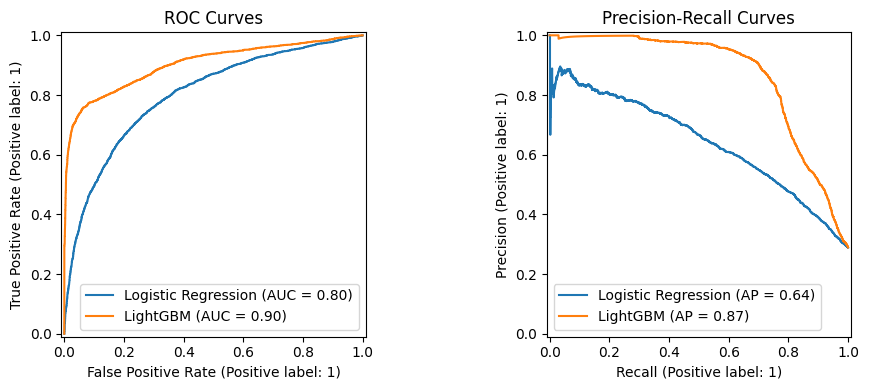

In [9]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# ROC Curve
RocCurveDisplay.from_predictions(y_test, y_prob_base, ax=axes[0], name='Logistic Regression')
RocCurveDisplay.from_predictions(y_test, y_prob_lgb, ax=axes[0], name='LightGBM')
axes[0].set_title("ROC Curves")

# Precision-Recall Curve
PrecisionRecallDisplay.from_predictions(y_test, y_prob_base, ax=axes[1], name='Logistic Regression')
PrecisionRecallDisplay.from_predictions(y_test, y_prob_lgb, ax=axes[1], name='LightGBM')
axes[1].set_title("Precision-Recall Curves")

plt.tight_layout()
plt.savefig('../images/06_model_evaluation_curves.png', dpi=500)
plt.show()

###  Export Artifact

In [ ]:
# Models directory ensure karein
os.makedirs('../models', exist_ok=True)

# Save production LightGBM pipeline artifact
model_path = '../models/churn_production_pipeline.joblib'
joblib.dump(lgb_pipe, model_path)

print(f"Production pipeline successfully exported to: {model_path}")
print(f"File size: {os.path.getsize(model_path) / 1024:.2f} KB")

Production pipeline successfully exported to: ../models/churn_production_pipeline.joblib
File size: 509.67 KB
